# 12 学習済み Fashion-MNIST MLP：epoch 0を含むcheckpoint再選択と再現確認

Notebook 10で保存したTT-rank 16／32／64のcheckpointを**再学習せず**読み直し、保存済み評価値を再現します。そのうえで、TT置換直後のepoch 0もearly-stopping validation lossによるcheckpoint候補へ含めます。

このNotebookで行う処理はforward評価とstate dictの保存だけです。optimizerの生成、backpropagation、parameter更新、test set評価は行いません。したがって、ここでの選択は**epoch 0と保存済みtrained bestのpost-hoc二者比較**です。epoch 0を最初からbest checkpointとしてfine-tuningを再実行した場合のpatience軌跡を再現するものではありません。

## 1. 事前に固定する選択規則

Notebook 10の学習中と同じearly-stopping validation lossを選択基準にします。epoch 0のlossを $L_0$、保存済みbest checkpointのlossを $L_{\mathrm{best}}$、`MIN_DELTA`を $\delta$ とすると、

$$
L_0 - \delta > L_{\mathrm{best}}
$$

のときだけtrained bestを採用します。それ以外は、より早いepoch 0を維持します。rank-selection validation、accuracy、agreement、dense logitsとのRMSEは診断に使いますが、checkpoint選択には使いません。新規学習を行わないため、比較対象はNotebook 10が既に保存したtrained bestに限定されます。

In [1]:
# ============================================================
# importとプロジェクトルートの解決
# ============================================================
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import ast
import inspect
import json
import math
import sys
from pathlib import Path

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display

for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    src_dir = candidate / "src"
    if (src_dir / "nn_compression").is_dir():
        if str(src_dir) not in sys.path:
            sys.path.insert(0, str(src_dir))
        break
else:
    raise RuntimeError("src/nn_compression が見つかりません。")

# 学習済みdenseのfc1を指定modes・rankでTT化する。ここでは重みの追加学習はしない。
from nn_compression.compression import (
    TTLinear,
    factorize_named_tt_linear,
    tt_matrix_ranks,
)
from nn_compression.datasets import (
    get_fashion_mnist_datasets,
    make_fashion_mnist_loaders,
    split_fashion_mnist_dataset,
)
from nn_compression.metrics import (
    agreement,
    count_parameters,
    logits_rmse,
)
from nn_compression.models import MNISTMLP
from nn_compression.training import evaluate
from nn_compression.utils import (
    find_project_root,
    get_experiment_dirs,
    make_torch_generator,
    set_seed,
)

In [2]:
# Notebook 10と同じデータ条件・checkpoint選択条件を使う。
SEED = 0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
TARGET_LAYER = "fc1"
TRAIN_BATCH_SIZE = 64
VALIDATION_BATCH_SIZE = 64
RANK_VALIDATION_BATCH_SIZE = 512
LEARNING_RATE = 1e-3
MIN_DELTA = 1e-4
SAVE_RESULTS = True
LOSS_ATOL = 1e-6
RATE_ATOL = 1e-12
RMSE_ATOL = 1e-5

# 乱数条件をそろえる。loader用generatorのリセット・再作成も別に確認する。
set_seed(SEED)
project_root = find_project_root(Path.cwd())
data_dir, models_dir, results_dir = get_experiment_dirs(
    project_root,
    "30_tt_mps",
    "10_fashion_mnist_mlp",
    "12_epoch0_checkpoint_selection_and_reproducibility",
    create=False,
)
baseline_checkpoint_path = (
    project_root / "models" / "10_svd" / "20_fashion_mnist_mlp"
    / "03_mlp_svd_finetuning_using_src_corrected_rerun"
    / "baseline_same_run.pt"
)
selection_path = (
    project_root / "results" / "30_tt_mps" / "10_fashion_mnist_mlp"
    / "09_pretrained_mlp_fc1_tt_tensorization_comparison"
    / "selected_tensorizations.csv"
)
notebook10_results_dir = (
    project_root / "results" / "30_tt_mps" / "10_fashion_mnist_mlp"
    / "10_pretrained_mlp_fc1_tt_finetuning"
)
notebook10_models_dir = (
    project_root / "models" / "30_tt_mps" / "10_fashion_mnist_mlp"
    / "10_pretrained_mlp_fc1_tt_finetuning"
)
comparison_path = notebook10_results_dir / "finetuning_comparison.csv"
history_path = notebook10_results_dir / "finetuning_history.csv"
notebook10_path = (
    project_root / "notebooks" / "30_tt_mps" / "10_fashion_mnist_mlp"
    / "10_pretrained_mlp_fc1_tt_finetuning.ipynb"
)
notebook12_path = (
    project_root / "notebooks" / "30_tt_mps" / "10_fashion_mnist_mlp"
    / "12_epoch0_checkpoint_selection_and_reproducibility.ipynb"
)

required_input_paths = [
    baseline_checkpoint_path,
    selection_path,
    comparison_path,
    history_path,
    notebook10_path,
]
for required_path in required_input_paths:
    if not required_path.is_file():
        raise FileNotFoundError(f"必要な入力がありません: {required_path}")

print("device:", DEVICE)
print("Notebook 10 results:", notebook10_results_dir)
print("Notebook 12 results target:", results_dir)

device: cuda
Notebook 10 results: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\10_fashion_mnist_mlp\10_pretrained_mlp_fc1_tt_finetuning
Notebook 12 results target: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\10_fashion_mnist_mlp\12_epoch0_checkpoint_selection_and_reproducibility


## 2. 09・10の保存結果を読み込む

09の選択表をモデル再構築の仕様として使い、10の比較表・履歴表を再現対象として読み込みます。CSV中のtuple文字列だけを`ast.literal_eval`で安全にtupleへ戻します。

In [3]:
# 前Notebookの保存表を読み、候補仕様と評価結果を接続する。
df_selected = pd.read_csv(selection_path)
# 前Notebookの保存表を読み、候補仕様と評価結果を接続する。
df_saved_comparison = pd.read_csv(comparison_path)
# 前Notebookの保存表を読み、候補仕様と評価結果を接続する。
df_saved_history = pd.read_csv(history_path)

for frame in [df_selected, df_saved_comparison]:
    for column in ["out_modes", "in_modes", "actual_ranks"]:
        if column in frame.columns:
            # CSVで文字列になったtupleを元の型へ戻す。任意コードを実行するevalは使わない。
            frame[column] = frame[column].map(
                lambda value: tuple(ast.literal_eval(value))
                if isinstance(value, str)
                else tuple(value)
            )

role_order = ["aggressive", "balanced", "conservative"]
expected_ranks = {"aggressive": 16, "balanced": 32, "conservative": 64}
required_selection_columns = {
    "selection_role", "tensorization", "out_modes", "in_modes",
    "requested_rank", "actual_ranks", "model_parameters",
}
required_comparison_columns = {
    "selection_role", "validation_loss_after",
    "validation_accuracy_after", "prediction_agreement_after",
    "logits_rmse_after", "best_epoch", "best_validation_loss",
}
if missing := required_selection_columns.difference(df_selected.columns):
    raise ValueError(f"09の選択CSVに必須列がありません: {sorted(missing)}")
if missing := required_comparison_columns.difference(df_saved_comparison.columns):
    raise ValueError(f"10の比較CSVに必須列がありません: {sorted(missing)}")

assert set(df_selected["selection_role"]) == set(role_order)
assert set(df_saved_comparison["selection_role"]) == set(role_order)
assert set(df_saved_history["selection_role"]) == set(role_order)
assert not df_selected["selection_role"].duplicated().any()
assert not df_saved_comparison["selection_role"].duplicated().any()

for role, expected_rank in expected_ranks.items():
    selection_row = df_selected.loc[df_selected["selection_role"] == role].iloc[0]
    assert selection_row["tensorization"] == "reversed_sites"
    assert int(selection_row["requested_rank"]) == expected_rank
    checkpoint_file = notebook10_models_dir / f"{role}_finetuned.pt"
    if not checkpoint_file.is_file():
        raise FileNotFoundError(f"Notebook 10のcheckpointがありません: {checkpoint_file}")

display(df_selected[[
    "selection_role", "tensorization", "out_modes", "in_modes",
    "requested_rank", "actual_ranks", "model_parameters",
]])

,selection_role,tensorization,out_modes,in_modes,requested_rank,actual_ranks,model_parameters
0,aggressive,reversed_sites,"(32, 8, 2)","(2, 8, 49)",16,"(1, 16, 16, 1)",153386
1,balanced,reversed_sites,"(32, 8, 2)","(2, 8, 49)",32,"(1, 32, 32, 1)",205130
2,conservative,reversed_sites,"(32, 8, 2)","(2, 8, 49)",64,"(1, 64, 64, 1)",406922


## 3. 同じデータ分割とdense baselineを再現する

seed 0でFashion-MNISTの学習側60,000件を50,000／5,000／5,000へ分けます。このNotebookが評価するのは後半2つだけです。test datasetはloader作成APIに渡すだけで、評価ループへ渡しません。

In [4]:
# 乱数条件をそろえる。loader用generatorのリセット・再作成も別に確認する。
set_seed(SEED)
full_train_dataset, test_dataset_reserved = get_fashion_mnist_datasets(
    data_dir,
    download=False,
)
train_dataset, early_stopping_dataset, rank_validation_dataset = (
    split_fashion_mnist_dataset(
        full_train_dataset,
        (50_000, 5_000, 5_000),
        seed=SEED,
    )
)
# 用途別loaderを作る。test loaderが返っても評価に使用しない。
loaders = make_fashion_mnist_loaders(
    train_dataset,
    early_stopping_dataset,
    test_dataset_reserved,
    train_batch_size=TRAIN_BATCH_SIZE,
    validation_batch_size=VALIDATION_BATCH_SIZE,
    test_batch_size=1000,
    rank_validation_dataset=rank_validation_dataset,
    train_generator=make_torch_generator(SEED),
)
early_stopping_loader = loaders["validation_loader"]
rank_validation_loader = loaders["validation_loader_rank"]
criterion = torch.nn.CrossEntropyLoss()

baseline_state = torch.load(
    baseline_checkpoint_path,
    map_location=DEVICE,
    weights_only=True,
)
# 別モデルを作り、baselineから独立に候補を構築する。前候補の学習結果は引き継がない。
baseline_model = MNISTMLP().to(device=DEVICE, dtype=DTYPE)
# 既存の構造へcheckpointのTensor値を読み込む。rankとparameter名が一致する構造が必要。
baseline_model.load_state_dict(baseline_state)
baseline_model.eval()
# このloader上のlossとaccuracyを測る。選択用と診断用のデータを区別する。
baseline_early_loss, baseline_early_accuracy = evaluate(
    baseline_model, early_stopping_loader, criterion, DEVICE
)
# このloader上のlossとaccuracyを測る。選択用と診断用のデータを区別する。
baseline_rank_loss, baseline_rank_accuracy = evaluate(
    baseline_model, rank_validation_loader, criterion, DEVICE
)
# 総parameter要素数を数える。更新対象だけの数とは区別する。
baseline_parameters = count_parameters(baseline_model)

assert len(train_dataset) == 50_000
assert len(early_stopping_dataset) == 5_000
assert len(rank_validation_dataset) == 5_000
assert len(test_dataset_reserved) == 10_000
assert isinstance(baseline_model.fc1, torch.nn.Linear)
print(f"dense early-stop: loss={baseline_early_loss:.6f}, accuracy={baseline_early_accuracy:.4f}")
print(f"dense rank-validation: loss={baseline_rank_loss:.6f}, accuracy={baseline_rank_accuracy:.4f}")
print("test set: reserved and not evaluated")

dense early-stop: loss=0.299885, accuracy=0.8838
dense rank-validation: loss=0.310588, accuracy=0.8884
test set: reserved and not evaluated


## 4. Notebook 10の実装契約を監査する

Notebook 10のsourceと既存`src`実装を読み、fine-tuning条件を表に固定します。これは再学習ではなく、今回の比較対象がどの条件で作られたかを明示する監査です。

In [5]:
# 10と既存srcの実装を読み、loss・optimizer・選択条件を監査する。再学習はしない。
# 元fitがepoch 0をbest候補に含めていなかったことを、選択規則の問題として切り分ける。

with notebook10_path.open("r", encoding="utf-8") as file:
    notebook10_json = json.load(file)
notebook10_code = "\n".join(
    "".join(cell.get("source", []))
    for cell in notebook10_json["cells"]
    if cell.get("cell_type") == "code"
)

# 既存APIのsourceも確認し、選択規則とRMSE集計方法を監査する。
import nn_compression.metrics.model_comparison as model_comparison_module
import nn_compression.training.fit as fit_module

fit_source = inspect.getsource(fit_module.fit_with_early_stopping)
rmse_source = inspect.getsource(model_comparison_module.logits_rmse)
# この試行の更新対象に新しいAdamを用意する。optimizer生成だけでは重みは更新されない。
adam_weight_decay_default = inspect.signature(
    torch.optim.Adam.__init__
).parameters["weight_decay"].default

# 既存の構造へcheckpointのTensor値を読み込む。rankとparameter名が一致する構造が必要。
audit_checks = [
    ("loss", "CrossEntropyLoss only", "torch.nn.CrossEntropyLoss()" in notebook10_code,
     "Notebook 10 creates only CrossEntropyLoss; no distillation loss"),
    ("optimizer", "Adam", "torch.optim.Adam" in notebook10_code,
     "a new Adam is constructed inside each role loop"),
    ("learning_rate", "1e-3", "LEARNING_RATE = 1e-3" in notebook10_code,
     "Notebook 10 configuration"),
    ("weight_decay", "0", adam_weight_decay_default == 0,
     "Adam default; Notebook 10 does not override weight_decay"),
    ("scheduler", "none", "scheduler" not in notebook10_code.lower(),
     "no scheduler is constructed or stepped"),
    ("seed", "0", "SEED = 0" in notebook10_code,
     "seed and train Generator are reset for each role"),
    ("dense_initialization", "same checkpoint",
     "dense_model.load_state_dict(baseline_state)" in notebook10_code,
     "each role starts from baseline_state before TT conversion"),
    ("optimizer_independence", "independent by role",
     "for row in df_selected.itertuples(index=False):" in notebook10_code,
     "Adam construction is inside the role loop"),
    ("best_checkpoint_criterion", "early-stop validation loss",
     "best_validation_loss - min_delta > validation_loss" in fit_source,
     "fit_with_early_stopping uses strict min_delta improvement"),
    ("epoch0_originally_included", "no",
     "best_validation_loss = float(\"inf\")" in fit_source,
     "original fit initializes best at infinity and evaluates after epoch 1"),
    ("evaluation_mode", "eval plus no_grad",
     "model.eval()" in inspect.getsource(evaluate),
     "existing evaluate API controls inference mode"),
    ("logits_rmse", "global over all logit elements",
     "difference.square().sum().item()" in rmse_source
     and "difference.numel()" in rmse_source,
     "sum squared error divided by all logit elements, then square root"),
]
df_implementation_audit = pd.DataFrame(
    [
        {"item": item, "expected": expected,
         "status": "PASS" if passed else "FAIL", "evidence": evidence}
        for item, expected, passed, evidence in audit_checks
    ]
)
assert (df_implementation_audit["status"] == "PASS").all()
display(df_implementation_audit)

,item,expected,status,evidence
0,loss,CrossEntropyLoss only,PASS,Notebook 10 creates only CrossEntropyLoss; no ...
1,optimizer,Adam,PASS,a new Adam is constructed inside each role loop
2,learning_rate,1e-3,PASS,Notebook 10 configuration
3,weight_decay,0,PASS,Adam default; Notebook 10 does not override we...
4,scheduler,none,PASS,no scheduler is constructed or stepped
5,seed,0,PASS,seed and train Generator are reset for each role
6,dense_initialization,same checkpoint,PASS,each role starts from baseline_state before TT...
7,optimizer_independence,independent by role,PASS,Adam construction is inside the role loop
8,best_checkpoint_criterion,early-stop validation loss,PASS,fit_with_early_stopping uses strict min_delta ...
9,epoch0_originally_included,no,PASS,original fit initializes best at infinity and ...


## 5. epoch 0と保存済みbest checkpointを再構築・再評価する

各roleについて同じdense checkpointから2つのTTモデルを作ります。1つはTT-SVD直後のepoch 0、もう1つは同じ構造へNotebook 10のstate dictを読み込んだtrained bestです。

TT coresのshape、実rank、parameter数が09・10の保存値と一致することも確認します。

In [6]:
# 同じdense重みからepoch 0モデルと保存済みtrained best用モデルを別々に作る。
# L0-delta>Ltrained、すなわちL0-Ltrained>deltaのときだけtrained bestを選ぶ。
# これは保存済み2候補の事後比較。epoch 0を初期bestとして学習し直す処理ではない。
# 初期bestを変えるとpatienceの軌跡も変わり得るが、ここでは再計算しない。
# 保存済み結果では16と32はtrained best、64はepoch 0が選ばれた。
# accuracyが高いかではなく、early-stopping lossの規則に沿って選んだ結果である。
# accuracyはargmaxが正解labelと一致した割合で、予測確率の確信度までは測らない。
# CrossEntropyLossは正解クラス確率p_yに対して-log(p_y)。softmaxを代入すると-z_y+log(sum(exp(z_c)))。
# 正解確率0.3のlossは約1.204、0.001は約6.908。同じ不正解でも確信の強い誤りは大きく罰せられる。
# 正解数が増えても一部の誤りの確信度が強まれば平均lossは増え得る。今回はその原因を特定したわけではない。
# early-stopping lossとrank-validation accuracyはデータ集合も異なるので、同じ画像上の変化として断定しない。
# logits RMSE=sqrt(sum((z_TT-z_dense)**2)/(N*C))。batchごとのRMSEを単純平均する量ではない。
# 各画像の全logitsに定数aを足すとsoftmaxの分子分母のexp(a)が消え、argmaxと確率は不変だがRMSEは変わり得る。
# label lossだけで学習するならdense logitsの再現は直接の目的ではない。accuracy回復とRMSE改善は別に読む。

comparison_records = []
reproduction_records = []
selected_records = []
selected_models = {}

for role in role_order:
    selection_row = df_selected.loc[df_selected["selection_role"] == role].iloc[0]
    saved_row = df_saved_comparison.loc[
        df_saved_comparison["selection_role"] == role
    ].iloc[0]
    out_modes = tuple(selection_row["out_modes"])
    in_modes = tuple(selection_row["in_modes"])
    requested_rank = int(selection_row["requested_rank"])

    # epoch 0: dense baselineからTT-SVDで再構築する。
    # 別モデルを作り、baselineから独立に候補を構築する。前候補の学習結果は引き継がない。
    epoch0_dense = MNISTMLP().to(device=DEVICE, dtype=DTYPE)
    # 既存の構造へcheckpointのTensor値を読み込む。rankとparameter名が一致する構造が必要。
    epoch0_dense.load_state_dict(baseline_state)
    # 学習済みdenseのfc1を指定modes・rankでTT化する。ここでは重みの追加学習はしない。
    epoch0_model = factorize_named_tt_linear(
        epoch0_dense, TARGET_LAYER, out_modes, in_modes,
        max_rank=requested_rank,
    )

    # trained best: 同じTT構造へNotebook 10の保存state dictを読む。
    # 別モデルを作り、baselineから独立に候補を構築する。前候補の学習結果は引き継がない。
    trained_dense = MNISTMLP().to(device=DEVICE, dtype=DTYPE)
    # 既存の構造へcheckpointのTensor値を読み込む。rankとparameter名が一致する構造が必要。
    trained_dense.load_state_dict(baseline_state)
    # 学習済みdenseのfc1を指定modes・rankでTT化する。ここでは重みの追加学習はしない。
    trained_model = factorize_named_tt_linear(
        trained_dense, TARGET_LAYER, out_modes, in_modes,
        max_rank=requested_rank,
    )
    trained_checkpoint_path = notebook10_models_dir / f"{role}_finetuned.pt"
    trained_state = torch.load(
        trained_checkpoint_path, map_location=DEVICE, weights_only=True
    )
    # 既存の構造へcheckpointのTensor値を読み込む。rankとparameter名が一致する構造が必要。
    trained_model.load_state_dict(trained_state, strict=True)

    assert isinstance(epoch0_model.fc1, TTLinear)
    assert isinstance(trained_model.fc1, TTLinear)
    # coreの実際の結合次元を読む。指定上限rankとは別に検証する。
    epoch0_ranks = tt_matrix_ranks(list(epoch0_model.fc1.cores))
    # coreの実際の結合次元を読む。指定上限rankとは別に検証する。
    trained_ranks = tt_matrix_ranks(list(trained_model.fc1.cores))
    assert epoch0_ranks == trained_ranks == tuple(selection_row["actual_ranks"])
    # 総parameter要素数を数える。更新対象だけの数とは区別する。
    assert count_parameters(epoch0_model) == count_parameters(trained_model)
    # 総parameter要素数を数える。更新対象だけの数とは区別する。
    assert count_parameters(epoch0_model) == int(selection_row["model_parameters"])

    role_metrics = {}
    for source, candidate_model in [
        ("epoch0", epoch0_model),
        ("trained_best", trained_model),
    ]:
        candidate_model.eval()
        # このloader上のlossとaccuracyを測る。選択用と診断用のデータを区別する。
        early_loss, early_accuracy = evaluate(
            candidate_model, early_stopping_loader, criterion, DEVICE
        )
        # このloader上のlossとaccuracyを測る。選択用と診断用のデータを区別する。
        rank_loss, rank_accuracy = evaluate(
            candidate_model, rank_validation_loader, criterion, DEVICE
        )
        # 正解labelではなくdenseのargmax予測との一致率を測る。
        rank_agreement = agreement(
            baseline_model, candidate_model, rank_validation_loader, DEVICE
        )
        # denseとの全logit要素の二乗差を平均し、その平方根を測る。
        rank_rmse = logits_rmse(
            baseline_model, candidate_model, rank_validation_loader, DEVICE
        )
        role_metrics[source] = {
            "early_stopping_loss": early_loss,
            "early_stopping_accuracy": early_accuracy,
            "rank_validation_loss": rank_loss,
            "rank_validation_accuracy": rank_accuracy,
            "prediction_agreement": rank_agreement,
            "logits_rmse": rank_rmse,
        }

    trained_improves = (
        role_metrics["epoch0"]["early_stopping_loss"] - MIN_DELTA
        > role_metrics["trained_best"]["early_stopping_loss"]
    )
    selected_source = "trained_best" if trained_improves else "epoch0"
    selected_epoch = int(saved_row["best_epoch"]) if trained_improves else 0
    selected_model = trained_model if trained_improves else epoch0_model
    selected_models[role] = selected_model

    for source in ["epoch0", "trained_best"]:
        # 総parameter要素数を数える。更新対象だけの数とは区別する。
        comparison_records.append({
            "selection_role": role,
            "tensorization": selection_row["tensorization"],
            "out_modes": out_modes,
            "in_modes": in_modes,
            "requested_rank": requested_rank,
            "actual_ranks": epoch0_ranks,
            "checkpoint_source": source,
            "epoch": 0 if source == "epoch0" else int(saved_row["best_epoch"]),
            "is_selected": source == selected_source,
            "model_parameters": count_parameters(selected_model),
            "model_compression_ratio": baseline_parameters / count_parameters(selected_model),
            **role_metrics[source],
        })

    # 総parameter要素数を数える。更新対象だけの数とは区別する。
    selected_records.append({
        "selection_role": role,
        "tensorization": selection_row["tensorization"],
        "out_modes": out_modes,
        "in_modes": in_modes,
        "requested_rank": requested_rank,
        "actual_ranks": epoch0_ranks,
        "selection_source": selected_source,
        "selected_epoch": selected_epoch,
        "selection_criterion": "early_stopping_validation_loss",
        "selection_scope": "post_hoc_epoch0_vs_saved_trained_best",
        "retraining_performed": False,
        "patience_trajectory_recomputed": False,
        "min_delta": MIN_DELTA,
        "model_parameters": count_parameters(selected_model),
        "model_compression_ratio": baseline_parameters / count_parameters(selected_model),
        **role_metrics[selected_source],
    })

    # Notebook 10保存値と、trained checkpointのfresh評価値を照合する。
    fresh_trained = role_metrics["trained_best"]
    reproduction_row = {
        "selection_role": role,
        "requested_rank": requested_rank,
        "saved_best_validation_loss": float(saved_row["best_validation_loss"]),
        "fresh_best_validation_loss": fresh_trained["early_stopping_loss"],
        "saved_validation_loss_after": float(saved_row["validation_loss_after"]),
        "fresh_validation_loss_after": fresh_trained["rank_validation_loss"],
        "saved_validation_accuracy_after": float(saved_row["validation_accuracy_after"]),
        "fresh_validation_accuracy_after": fresh_trained["rank_validation_accuracy"],
        "saved_prediction_agreement_after": float(saved_row["prediction_agreement_after"]),
        "fresh_prediction_agreement_after": fresh_trained["prediction_agreement"],
        "saved_logits_rmse_after": float(saved_row["logits_rmse_after"]),
        "fresh_logits_rmse_after": fresh_trained["logits_rmse"],
    }
    reproduction_row["best_validation_loss_abs_diff"] = abs(
        reproduction_row["saved_best_validation_loss"]
        - reproduction_row["fresh_best_validation_loss"]
    )
    reproduction_row["validation_loss_abs_diff"] = abs(
        reproduction_row["saved_validation_loss_after"]
        - reproduction_row["fresh_validation_loss_after"]
    )
    reproduction_row["validation_accuracy_abs_diff"] = abs(
        reproduction_row["saved_validation_accuracy_after"]
        - reproduction_row["fresh_validation_accuracy_after"]
    )
    reproduction_row["prediction_agreement_abs_diff"] = abs(
        reproduction_row["saved_prediction_agreement_after"]
        - reproduction_row["fresh_prediction_agreement_after"]
    )
    reproduction_row["logits_rmse_abs_diff"] = abs(
        reproduction_row["saved_logits_rmse_after"]
        - reproduction_row["fresh_logits_rmse_after"]
    )
    reproduction_row["reproduction_passed"] = (
        reproduction_row["best_validation_loss_abs_diff"] <= LOSS_ATOL
        and reproduction_row["validation_loss_abs_diff"] <= LOSS_ATOL
        and reproduction_row["validation_accuracy_abs_diff"] <= RATE_ATOL
        and reproduction_row["prediction_agreement_abs_diff"] <= RATE_ATOL
        and reproduction_row["logits_rmse_abs_diff"] <= RMSE_ATOL
    )
    reproduction_records.append(reproduction_row)
    print(
        f"{role}: epoch0 early loss="
        f"{role_metrics['epoch0']['early_stopping_loss']:.6f}, "
        f"trained={role_metrics['trained_best']['early_stopping_loss']:.6f} "
        f"-> selected={selected_source}"
    )

df_epoch0_checkpoint_comparison = pd.DataFrame(comparison_records)
df_checkpoint_reproduction = pd.DataFrame(reproduction_records)
df_selected_checkpoint_metrics = pd.DataFrame(selected_records)

assert len(df_epoch0_checkpoint_comparison) == 6
assert len(df_selected_checkpoint_metrics) == 3
assert len(selected_models) == 3
assert df_checkpoint_reproduction["reproduction_passed"].all()
display(df_checkpoint_reproduction.round(8))
display(df_epoch0_checkpoint_comparison.round(6))
display(df_selected_checkpoint_metrics.round(6))

aggressive: epoch0 early loss=1.308600, trained=0.305269 -> selected=trained_best
balanced: epoch0 early loss=0.509134, trained=0.310279 -> selected=trained_best
conservative: epoch0 early loss=0.298593, trained=0.324507 -> selected=epoch0


,selection_role,requested_rank,saved_best_validation_loss,fresh_best_validation_loss,saved_validation_loss_after,fresh_validation_loss_after,saved_validation_accuracy_after,fresh_validation_accuracy_after,saved_prediction_agreement_after,fresh_prediction_agreement_after,saved_logits_rmse_after,fresh_logits_rmse_after,best_validation_loss_abs_diff,validation_loss_abs_diff,validation_accuracy_abs_diff,prediction_agreement_abs_diff,logits_rmse_abs_diff,reproduction_passed
0,aggressive,16,0.305269,0.305269,0.308215,0.308215,0.889,0.889,0.9314,0.9314,3.666437,3.666437,0.0,0.0,0.0,0.0,0.0,True
1,balanced,32,0.310279,0.310279,0.325543,0.325543,0.885,0.885,0.9298,0.9298,7.104990,7.104990,0.0,0.0,0.0,0.0,0.0,True
2,conservative,64,0.324507,0.324507,0.324577,0.324577,0.885,0.885,0.9208,0.9208,11.700915,11.700915,0.0,0.0,0.0,0.0,0.0,True


,selection_role,tensorization,out_modes,in_modes,requested_rank,actual_ranks,checkpoint_source,epoch,is_selected,model_parameters,model_compression_ratio,early_stopping_loss,early_stopping_accuracy,rank_validation_loss,rank_validation_accuracy,prediction_agreement,logits_rmse
0,aggressive,reversed_sites,"(32, 8, 2)","(2, 8, 49)",16,"(1, 16, 16, 1)",epoch0,0,False,153386,3.493265,1.308600,0.5110,1.302497,0.5116,0.5276,7.933703
1,aggressive,reversed_sites,"(32, 8, 2)","(2, 8, 49)",16,"(1, 16, 16, 1)",trained_best,5,True,153386,3.493265,0.305269,0.8868,0.308215,0.8890,0.9314,3.666437
2,balanced,reversed_sites,"(32, 8, 2)","(2, 8, 49)",32,"(1, 32, 32, 1)",epoch0,0,False,205130,2.612090,0.509134,0.7946,0.514218,0.7980,0.8460,4.451787
3,balanced,reversed_sites,"(32, 8, 2)","(2, 8, 49)",32,"(1, 32, 32, 1)",trained_best,5,True,205130,2.612090,0.310279,0.8912,0.325543,0.8850,0.9298,7.104990
4,conservative,reversed_sites,"(32, 8, 2)","(2, 8, 49)",64,"(1, 64, 64, 1)",epoch0,0,True,406922,1.316758,0.298593,0.8830,0.310711,0.8872,0.9922,0.179470
5,conservative,reversed_sites,"(32, 8, 2)","(2, 8, 49)",64,"(1, 64, 64, 1)",trained_best,6,False,406922,1.316758,0.324507,0.8888,0.324577,0.8850,0.9208,11.700915


,selection_role,tensorization,out_modes,in_modes,requested_rank,actual_ranks,selection_source,selected_epoch,selection_criterion,selection_scope,...,patience_trajectory_recomputed,min_delta,model_parameters,model_compression_ratio,early_stopping_loss,early_stopping_accuracy,rank_validation_loss,rank_validation_accuracy,prediction_agreement,logits_rmse
0,aggressive,reversed_sites,"(32, 8, 2)","(2, 8, 49)",16,"(1, 16, 16, 1)",trained_best,5,early_stopping_validation_loss,post_hoc_epoch0_vs_saved_trained_best,...,False,0.0001,153386,3.493265,0.305269,0.8868,0.308215,0.8890,0.9314,3.666437
1,balanced,reversed_sites,"(32, 8, 2)","(2, 8, 49)",32,"(1, 32, 32, 1)",trained_best,5,early_stopping_validation_loss,post_hoc_epoch0_vs_saved_trained_best,...,False,0.0001,205130,2.612090,0.310279,0.8912,0.325543,0.8850,0.9298,7.104990
2,conservative,reversed_sites,"(32, 8, 2)","(2, 8, 49)",64,"(1, 64, 64, 1)",epoch0,0,early_stopping_validation_loss,post_hoc_epoch0_vs_saved_trained_best,...,False,0.0001,406922,1.316758,0.298593,0.8830,0.310711,0.8872,0.9922,0.179470


## 6. epoch 0とtrained bestを可視化する

左は実際の選択基準であるearly-stopping validation loss、右は選択に使わないrank-validation accuracyです。accuracy図には比較対象としてdense baselineを黒い破線で示します。

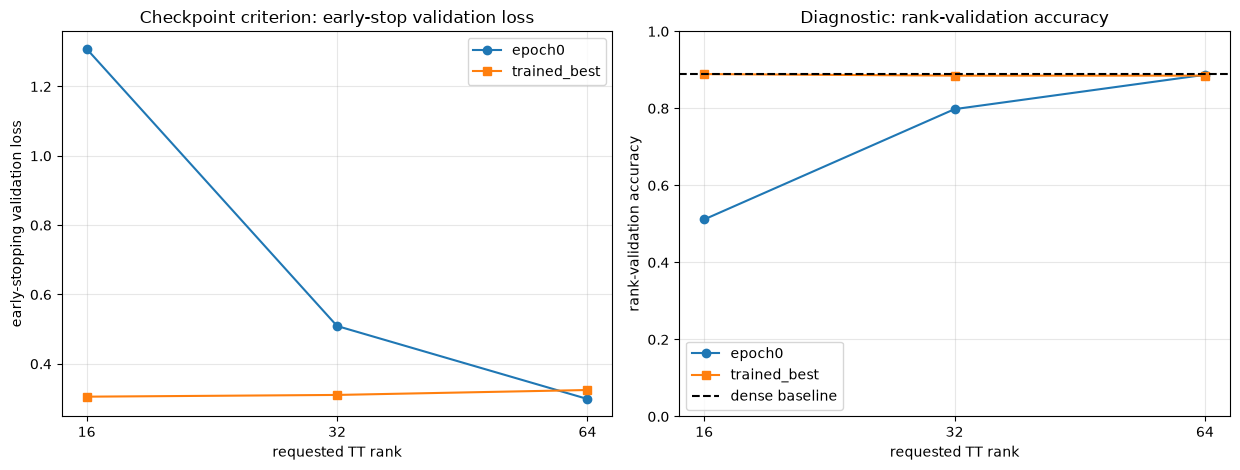

In [7]:
fig_checkpoint_comparison, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
colors = {"epoch0": "tab:blue", "trained_best": "tab:orange"}
markers = {"epoch0": "o", "trained_best": "s"}

for source in ["epoch0", "trained_best"]:
    subset = (
        df_epoch0_checkpoint_comparison.loc[
            df_epoch0_checkpoint_comparison["checkpoint_source"] == source
        ]
        .sort_values("requested_rank")
    )
    axes[0].plot(
        subset["requested_rank"], subset["early_stopping_loss"],
        marker=markers[source], color=colors[source], label=source,
    )
    axes[1].plot(
        subset["requested_rank"], subset["rank_validation_accuracy"],
        marker=markers[source], color=colors[source], label=source,
    )

axes[0].set_title("Checkpoint criterion: early-stop validation loss")
axes[0].set_xlabel("requested TT rank")
axes[0].set_ylabel("early-stopping validation loss")
axes[1].axhline(
    baseline_rank_accuracy, color="black", linestyle="--",
    label="dense baseline",
)
axes[1].set_title("Diagnostic: rank-validation accuracy")
axes[1].set_xlabel("requested TT rank")
axes[1].set_ylabel("rank-validation accuracy")
axes[1].set_ylim(0.0, 1.0)
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks([16, 32, 64], labels=["16", "32", "64"])
    ax.grid(True, alpha=0.3)
    ax.legend()
fig_checkpoint_comparison.tight_layout()
plt.show()

## 7. 監査結果・再現結果・再選択結果を別名で保存する

Notebook 10の成果物は上書きしません。12専用のresults／modelsディレクトリへ、監査表、再現照合表、候補比較表、選択結果、図、roleごとのselected state dictを保存します。

In [8]:
if SAVE_RESULTS:
    results_dir.mkdir(parents=True, exist_ok=True)
    models_dir.mkdir(parents=True, exist_ok=True)

    # 抽出した表を独立に編集し、元の比較表を変更しない。
    audit_to_save = df_implementation_audit.copy()
    # 抽出した表を独立に編集し、元の比較表を変更しない。
    reproduction_to_save = df_checkpoint_reproduction.copy()
    # 抽出した表を独立に編集し、元の比較表を変更しない。
    comparison_to_save = df_epoch0_checkpoint_comparison.copy()
    # 抽出した表を独立に編集し、元の比較表を変更しない。
    selected_to_save = df_selected_checkpoint_metrics.copy()
    for frame in [comparison_to_save, selected_to_save]:
        for column in ["out_modes", "in_modes", "actual_ranks"]:
            frame[column] = frame[column].map(str)

    # 整理済みの表を保存する。数値の再評価やモデル学習は行わない。
    audit_to_save.to_csv(results_dir / "implementation_audit.csv", index=False)
    # 整理済みの表を保存する。数値の再評価やモデル学習は行わない。
    reproduction_to_save.to_csv(
        results_dir / "checkpoint_reproduction.csv", index=False
    )
    # 整理済みの表を保存する。数値の再評価やモデル学習は行わない。
    comparison_to_save.to_csv(
        results_dir / "epoch0_checkpoint_comparison.csv", index=False
    )
    # 整理済みの表を保存する。数値の再評価やモデル学習は行わない。
    selected_to_save.to_csv(
        results_dir / "selected_checkpoint_metrics.csv", index=False
    )
    # 作成済みのFigureを保存する。図は入力表に記録された結果を示す。
    fig_checkpoint_comparison.savefig(
        results_dir / "epoch0_checkpoint_comparison.png",
        dpi=150, bbox_inches="tight",
    )

    for role, selected_model in selected_models.items():
        # 選択済みparameterを保存する。モデル構造・optimizer・乱数の全情報を含むとは限らない。
        torch.save(
            selected_model.state_dict(),
            models_dir / f"{role}_selected.pt",
        )
    print("saved results:", results_dir)
    print("saved selected checkpoints:", models_dir)
else:
    print("SAVE_RESULTS=False: 保存していません。")

saved results: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\10_fashion_mnist_mlp\12_epoch0_checkpoint_selection_and_reproducibility
saved selected checkpoints: D:\dev\nn-compression-svd-dmrg\models\30_tt_mps\10_fashion_mnist_mlp\12_epoch0_checkpoint_selection_and_reproducibility


## 8. no-training・no-testの静的ガードと成果物確認

Notebook 12のコードセルをASTで検査し、optimizer生成、fit／train呼び出し、`backward()`、`step()`が無いことを確認します。また、評価APIへtest loaderを渡していないことを確認します。

In [9]:
# ASTで明示された学習呼び出しとtest評価の有無を検査する。
# 静的検査のPASSはこの監査項目が通った意味で、全ての動的副作用の不存在を証明するものではない。

with notebook12_path.open("r", encoding="utf-8") as file:
    notebook12_json = json.load(file)
code_sources = [
    "".join(cell.get("source", []))
    for cell in notebook12_json["cells"]
    if cell.get("cell_type") == "code"
]
for code_source in code_sources:
    tree = ast.parse(code_source)
    for node in ast.walk(tree):
        if not isinstance(node, ast.Call):
            continue
        if isinstance(node.func, ast.Name):
            assert node.func.id not in {"fit_with_early_stopping", "train_one_epoch"}
        if isinstance(node.func, ast.Attribute):
            assert node.func.attr not in {"backward", "step"}
            if (
                isinstance(node.func.value, ast.Attribute)
                and isinstance(node.func.value.value, ast.Name)
                and node.func.value.value.id == "torch"
                and node.func.value.attr == "optim"
            ):
                raise AssertionError("Notebook 12でoptimizerを生成してはいけません。")

# test loaderは存在するが、評価関数の引数には使っていない。
test_loader_key = "test_" + "loader"
assert test_loader_key in loaders
for code_source in code_sources:
    tree = ast.parse(code_source)
    for node in ast.walk(tree):
        if not isinstance(node, ast.Call):
            continue
        function_name = node.func.id if isinstance(node.func, ast.Name) else None
        if function_name in {"evaluate", "agreement", "logits_rmse"}:
            loader_argument_names = {
                argument.id for argument in node.args if isinstance(argument, ast.Name)
            }
            assert test_loader_key not in loader_argument_names

assert df_checkpoint_reproduction["reproduction_passed"].all()
assert df_selected_checkpoint_metrics["selection_source"].isin(
    ["epoch0", "trained_best"]
).all()
assert (df_selected_checkpoint_metrics["selected_epoch"] >= 0).all()

if SAVE_RESULTS:
    expected_outputs = [
        results_dir / "implementation_audit.csv",
        results_dir / "checkpoint_reproduction.csv",
        results_dir / "epoch0_checkpoint_comparison.csv",
        results_dir / "selected_checkpoint_metrics.csv",
        results_dir / "epoch0_checkpoint_comparison.png",
        *[models_dir / f"{role}_selected.pt" for role in role_order],
    ]
    for output_path in expected_outputs:
        assert output_path.is_file(), output_path

print("no-training / no-test / output verification: OK")

no-training / no-test / output verification: OK


## 9. 読み方と次への接続

このNotebookで`epoch0`が選ばれたroleでは、保存済みtrained bestが事前固定したvalidation loss基準でTT置換直後を上回っていません。これは再学習の失敗を断定するものではなく、epoch 0を候補に含めなかった元のcheckpoint選択をpost-hocに補正した結果です。epoch 0込みで学習をやり直した場合はpatienceの停止時点が変わり得ますが、このNotebookでは新規学習を行っていません。

dense logitsとのRMSEは診断指標です。Notebook 10は正解labelへのCross Entropyだけを最適化しているため、accuracyが回復してもRMSEが悪化することはあり得ます。

次のNotebookでは、ここで確定したepoch 0込みの基準を引き継いで、全parameter更新とTT cores-only更新を比較します。test setはまだ使用しません。